In [1]:
import numpy as np
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize
import pandas as pd

In [13]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

n = 300
eta = 0.01
decay_rate = 0.015
Lx = 32
Ly = 32

n2 = 30
eta_2 = 1

def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

def beta_crit_two_pop(d, eta, eta_2, decay_rate, Lx, N, N2):
    s0 = (N*eta + N2*eta_2)/(decay_rate*Lx**2)
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta)/(decay_rate*Lx**2)

In [17]:
metric = 'r4'  # 'pod' or 'r4' or 'pop'
if metric == 'pod':
    file = "edge_spen/component_reward_rand.csv"
    df = pd.read_csv(file)

    df['last50_pod_avg'] = df['pod_list'].apply(lambda x: np.mean(eval(x)[-1:]))
    results = df.groupby(['beta', 'delta'])['last50_pod_avg'].mean().unstack().to_numpy()

    # file = "edge_spen/component_reward_rand.csv"
    file_enh = 'component_reward_enh.csv'
    df_enh = pd.read_csv(file_enh)

    df_enh['last50_pod_avg'] = df_enh['pod_list'].apply(lambda x: np.mean(eval(x)[-1:]))
    results_enh = df_enh.groupby(['beta', 'delta'])['last50_pod_avg'].mean().unstack().to_numpy()

if metric == 'pop':
    file = "edge_spen/component_reward_rand.csv"
    df = pd.read_csv(file)

    df['last50_pop_avg'] = df['pop_list'].apply(lambda x: np.mean(eval(x)[-1:]))
    results = df.groupby(['beta', 'delta'])['last50_pop_avg'].mean().unstack().to_numpy()

    # file = "edge_spen/component_reward_rand.csv"
    file_enh = 'component_reward_enh.csv'
    df_enh = pd.read_csv(file_enh)

    df_enh['last50_pop_avg'] = df_enh['pop_list'].apply(lambda x: np.mean(eval(x)[-1:]))
    results_enh = df_enh.groupby(['beta', 'delta'])['last50_pop_avg'].mean().unstack().to_numpy()

if metric == 'r4':
    file = "edge_spen/r4_mean_50_rand.csv"
    df = pd.read_csv(file)
    results = df.groupby(['beta', 'delta'])['r4_mean_50'].mean().unstack().to_numpy()

    file_enh = 'r4_mean_50_enh.csv'
    df_enh = pd.read_csv(file_enh)
    results_enh = df_enh.groupby(['beta', 'delta'])['r4_mean_50'].mean().unstack().to_numpy()

In [18]:
results.shape

(9, 6)

In [19]:
def plot_order_parameter(op, beta_list, delta_list,
                         cmap='summer', two_populations=False):

    fig = plt.figure(figsize=(8,8), constrained_layout=True)
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    vmin, vmax = np.min(op), np.max(op)
    norm = Normalize(vmin=vmin, vmax=vmax)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)

    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i, j] = fig.add_subplot(gs[i, j])
            img = ax[i, j].imshow(
                np.ones((1, 1)) * (op[len(beta_list)-i-1, j]),
                cmap=cmap, norm=norm)
            
            ax[i, j].set_xticks([])
            ax[i, j].set_yticks([])

            if j == 0:
                ax[i, j].set_ylabel(
                    f'{beta_list[len(beta_list)-i-1]}',
                    fontsize=12
                )
            if i == len(beta_list)-1:
                ax[i, j].set_xlabel(
                    f'{delta_list[j]}',
                    fontsize=12
                )

    # Asse globale
    ax_curve = fig.add_subplot(gs[:,:], frameon=False)
    if not two_populations:
        ax_curve.plot(
            delta_list,
            [beta_crit(d, s0) for d in delta_list],
            color='red', linestyle='--', linewidth=2.5
        )
    else:
        ax_curve.plot(
            delta_list,
            [beta_crit_two_pop(d, eta, eta_2, decay_rate, Lx, n, n2) for d in delta_list],
            color='red', linestyle='--', linewidth=2.5
        )
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    # Shared colorbar (font!)
    cbar = fig.colorbar(
        img, ax=ax.ravel().tolist(),
        shrink=0.75, pad=0.1
    )
    cbar.ax.tick_params(labelsize=14)

    # Global labels
    fig.text(-0.05, 0.52, r'$\beta$', fontsize=18,
             va='center', rotation='vertical')
    fig.text(0.42, -0.03, r'$\delta$', fontsize=18,
             ha='center')

    plt.show()


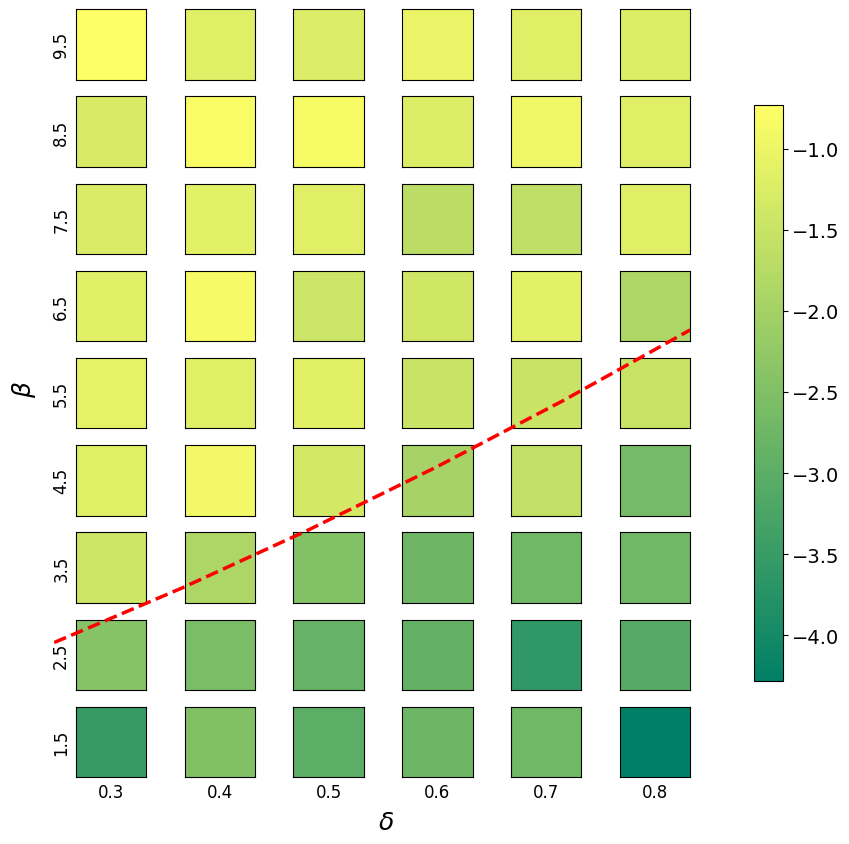

In [20]:
plot_order_parameter(results, beta_list, delta_list, cmap='summer', two_populations=True)

IndexError: index 8 is out of bounds for axis 0 with size 7

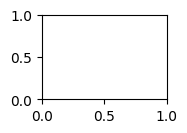

In [21]:
plot_order_parameter(results_enh, beta_list, delta_list, cmap='summer', two_populations=True)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

def plot_two_order_parameters(op1, op2, beta_list, delta_list,
                               main_title=r'$M(T)$',
                               cmap='summer', 
                               two_populations1=False, 
                               two_populations2=False,
                               titles=('Dataset 1', 'Dataset 2')):
    
    beta_arr = np.array(beta_list)
    delta_arr = np.array(delta_list)
    
    # 1. Calcolo dei confini (edges) delle celle
    d_edges = np.zeros(len(delta_arr) + 1)
    if len(delta_arr) > 1:
        d_edges[1:-1] = (delta_arr[:-1] + delta_arr[1:]) / 2.0
        d_edges[0] = delta_arr[0] - (delta_arr[1] - delta_arr[0]) / 2.0
        d_edges[-1] = delta_arr[-1] + (delta_arr[-1] - delta_arr[-2]) / 2.0
    else:
        d_edges = np.array([delta_arr[0] - 0.5, delta_arr[0] + 0.5])

    b_edges = np.zeros(len(beta_arr) + 1)
    if len(beta_arr) > 1:
        b_edges[1:-1] = (beta_arr[:-1] + beta_arr[1:]) / 2.0
        b_edges[0] = beta_arr[0] - (beta_arr[1] - beta_arr[0]) / 2.0
        b_edges[-1] = beta_arr[-1] + (beta_arr[-1] - beta_arr[-2]) / 2.0
    else:
        b_edges = np.array([beta_arr[0] - 0.5, beta_arr[0] + 0.5])

    extent = [d_edges[0], d_edges[-1], b_edges[0], b_edges[-1]]

    # 2. Scala colori unificata
    vmin = min(np.min(op1), np.min(op2))
    vmax = max(np.max(op1), np.max(op2))
    norm = Normalize(vmin=vmin, vmax=vmax)

    # 3. Creazione figura con proporzione verticale (10 x 8)
    fig, axes = plt.subplots(1, 2, figsize=(15, 8), constrained_layout=True)

    # Titolo principale
    if main_title:
        fig.suptitle(main_title, fontsize=20, fontweight='bold')

    ops = [op1, op2]
    two_pops = [two_populations1, two_populations2]

    fine_delta = np.linspace(delta_arr[0], delta_arr[-1], 200)

    for k in range(2):
        ax = axes[k]
        op = ops[k]
        two_pop = two_pops[k]

        img = ax.imshow(
            op, origin='lower', aspect='auto',
            extent=extent, cmap=cmap, norm=norm
        )

        if not two_pop:
            curve_beta = [beta_crit(d, s0) for d in fine_delta]
        else:
            curve_beta = [
                beta_crit_two_pop(d, eta, eta_2, decay_rate, Lx, n, n2) 
                for d in fine_delta
            ]

        ax.plot(fine_delta, curve_beta, color='red', linestyle='--', linewidth=2.5, label=r'$\beta_{crit}$')

        ax.set_xlim(d_edges[0], d_edges[-1])
        ax.set_ylim(b_edges[0], b_edges[-1])

        ax.set_xticks(delta_arr)
        ax.set_xticklabels([f'{d}' for d in delta_arr], fontsize=11)
        ax.set_yticks(beta_arr)
        ax.set_yticklabels([f'{b}' for b in beta_arr], fontsize=11)

        ax.set_title(titles[k], fontsize=14, pad=10, fontweight='semibold')
        ax.set_xlabel(r'$\delta$', fontsize=16, labelpad=8)
        ax.set_ylabel(r'$\beta$', fontsize=16, labelpad=8)

        ax.set_xticks(d_edges[:-1], minor=True)
        ax.set_yticks(b_edges[:-1], minor=True)
        ax.grid(True, which='minor', color='white', linestyle='-', linewidth=1, alpha=0.4)

    # Colorbar unica
    cbar = fig.colorbar(img, ax=axes.tolist(), shrink=0.85, pad=0.02)
    cbar.ax.tick_params(labelsize=12)

    plt.show()

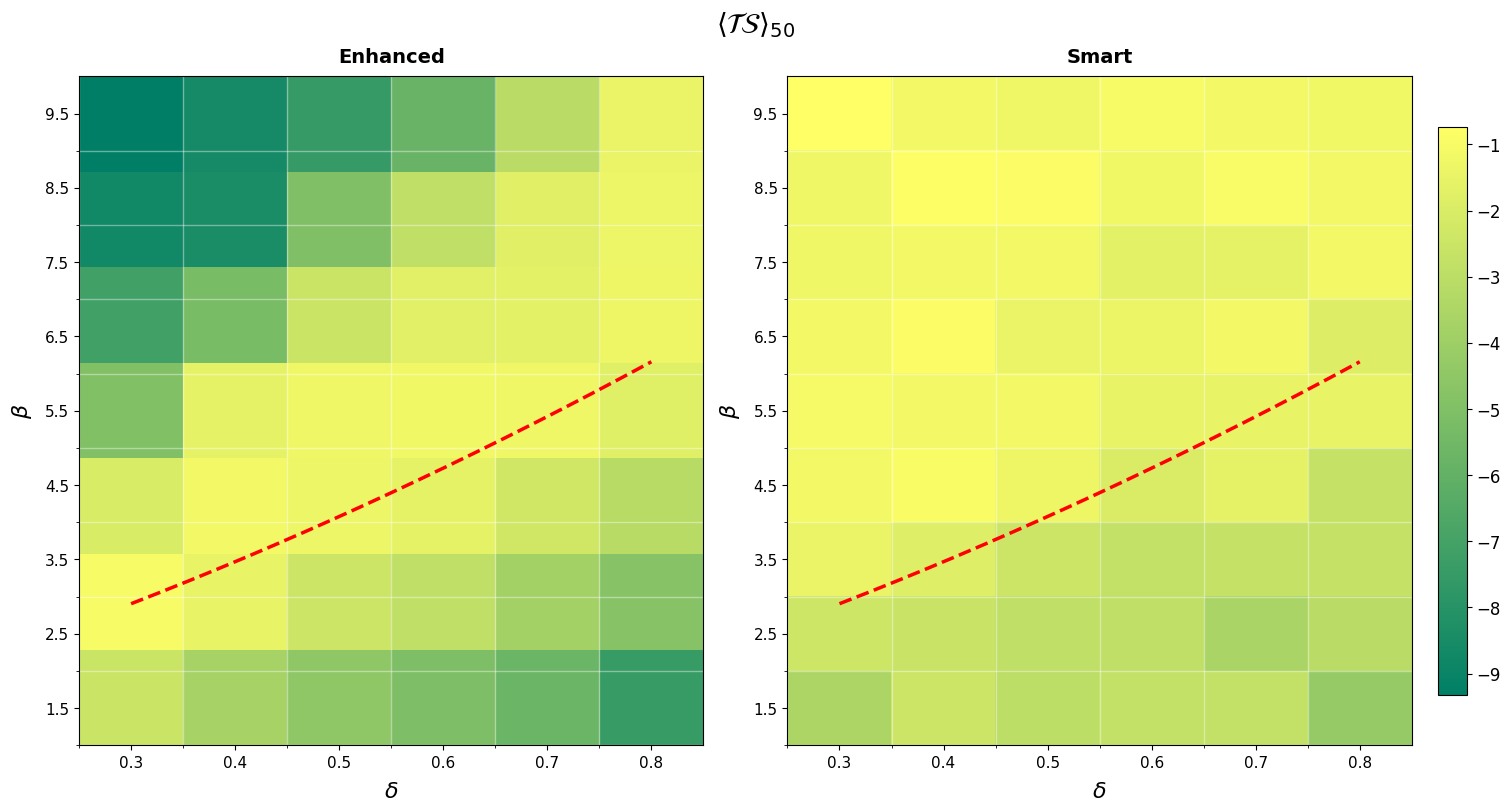

In [22]:
if metric == 'r4':
  main_title = r'$\langle \mathcal{TS} \rangle_{50}$'
if metric == 'pop':
  main_title = r'$m(T)$'
if metric == 'pod':
  main_title = r'$M(T)$'
plot_two_order_parameters(results_enh, results, beta_list, delta_list, cmap='summer',
                          two_populations1=True, two_populations2=True,
                            main_title=main_title,
                             titles=('Enhanced', 'Smart'))

In [12]:
results_enh

array([[-2.53907421, -3.74549619, -4.47685941, -5.08474932, -5.71150393,
        -7.44824639],
       [-1.01451532, -1.48115863, -2.45728235, -2.89879721, -3.8131448 ,
        -4.76466612],
       [-2.02729268, -1.18444605, -1.35992572, -1.62554804, -2.31703634,
        -3.12393363],
       [-4.93235762, -1.58747139, -1.2948096 , -1.20396794, -1.24349984,
        -1.81255831],
       [-7.09061488, -5.24765834, -2.539494  , -1.75354015, -1.65860835,
        -1.32464358],
       [-8.72498376, -8.43349783, -5.02002742, -2.8493634 , -1.79838888,
        -1.33399313],
       [-9.32468366, -8.56813355, -7.49775514, -5.78268436, -3.05686044,
        -1.46555673]])